# DEGs of All Cell Types

In [1]:
import numpy as np
import scanpy as sc
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import sparse
import pandas as pd
from Xenium_5K_IPF_constants import WORK_PATH, ALL_SUBTYPE_LIST

# Constant Declaration
deg_num = 500

# Option
sc.settings.verbosity = 3
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

In [2]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/integrated_anndata.h5ad")
celltype_df=pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")

In [3]:
adata = adata[celltype_df.index,].copy()

In [4]:
adata.obs = pd.merge(adata.obs, celltype_df[["cell_type", "cell_type_major", "subtype",]], left_index=True, right_index=True)
adata.raw = adata.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

normalizing counts per cell
    finished (0:00:01)


In [5]:
adata.obs["subtype"]=pd.Categorical(adata.obs["subtype"], categories=ALL_SUBTYPE_LIST)

In [6]:
sc.tl.dendrogram(adata, groupby="subtype")
sc.tl.rank_genes_groups(adata, groupby="subtype", use_raw=False, n_genes=adata.shape[1], method='wilcoxon')

computing PCA
    with n_comps=50


/tmp/ipykernel_3382/2289744281.py:1: UserWarning: You’re trying to run this on 5001 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  sc.tl.dendrogram(adata, groupby="subtype")


    finished (0:00:50)
Storing dendrogram info using `.uns['dendrogram_subtype']`
ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:01:49)


/home/s_nakamura/test_env/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/home/s_nakamura/test_env/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/home/s_nakamura/test_env/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:463: PerformanceWarning: DataFrame is h

In [7]:
rg = adata.uns["rank_genes_groups"]
groups = list(rg["names"].dtype.names)

gene_to_col = {g: i for i, g in enumerate(adata.var_names)}

# fraction array by each group
frac_by_group = {}
obs_grp = adata.obs["subtype"].values

for g in groups:
    mask = (obs_grp == g)
    n_cells = int(mask.sum())
    if n_cells == 0:
        frac_by_group[g] = np.zeros(adata.n_vars, dtype=float)
        continue

    subX = adata.X[mask, :].tocsr()
    hits = subX.copy()
    hits.data = (hits.data > 0).astype(np.int8)
    frac = np.asarray(hits.sum(axis=0)).ravel() / n_cells

    frac_by_group[g] = frac

In [8]:
subtype_deg_df = pd.DataFrame(columns=[i for i in range(deg_num*len(groups))], index=["subtype", "genes", "fractions", 'scores', 'pvals', 'pvals_adj', 'logfoldchanges'])

for n, g in enumerate(groups):
    for i in range(deg_num):
        subtype_deg_df.loc["subtype", i+deg_num*n]=g
        subtype_deg_df.loc["genes", i+deg_num*n]=rg["names"][i][n]
        subtype_deg_df.loc["fractions", i+deg_num*n]=frac_by_group[g][gene_to_col[rg["names"][i][n]]]
        for t in ['scores', 'pvals', 'pvals_adj', 'logfoldchanges']:
            subtype_deg_df.loc[t, i+deg_num*n]=rg[t][i][n].astype(np.float64)
subtype_df = subtype_deg_df.T
subtype_df.to_csv(f"{WORK_PATH}CSV/015_all_cell_type_degs.csv", index=False, encoding="utf-8-sig")

In [9]:
subtype_markers = {
    # =========================
    # Epithelial (7)
    # =========================
    "AT2": ["LAMP3", "ABCA3"],
    "AT1": ["AGER", "RTKN2"],
    "KRT5-/KRT17+": ["ITGB6", "CDKN2B"],
    "Basal": ["ANXA8", "TP63"],
    "Secretory": ["MET", "CDK14"],
    "Goblet": ["MUC5B", "FCGBP"],
    "Ciliated": ["FOXJ1", "TPPP3"],

    # =========================
    # Stromal (15)
    # =========================
    "Myofibroblast": ["POSTN", "CTHRC1"],
    "COMP+ fibroblast": ["COMP", "SFRP4"],
    "GREM1+ fibroblast": ["GREM1", "THBS1"],
    "Adventitial fibroblast": ["PI16", "CD34"],
    "Lipofibroblast": ["TCF21", "AOC3"],
    "Smooth muscle cell": ["MYLK", "CSRP1"],
    "Pericyte": ["PDGFRB", "NOTCH3"],
    "Alveolar Pericyte": ["KCNK3", "ADAMTSL3"],
    "Lymphatic": ["PROX1", "FLT4"],
    "Arteriole": ["GJA5", "VEGFC"],
    "Aerocyte": ["TBX2", "HPGD"],
    "General capillary": ["SLC6A4", "TMEM100"],
    "Venule": ["PLVAP", "CCL14"],
    "FRC-like": ["CCL19", "THY1"],
    "FDC-like": ["CXCL13", "CR2"],

    # =========================
    # Immune (17)
    # =========================
    "Monocyte": ["CD14", "FCN1"],
    "Interstitial macrophage": ["F13A1", "STAB1"],
    "SPP1+ macrophage": ["MMP9", "CTSL"],
    "CXCL9+ macrophage": ["CXCL9", "CXCL10"],
    "Alveolar macrophage": ["MARCO", "ALDH2"],
    "CD4+ T": ["CD3E", "CD4"],
    "CD8+ T": ["CD8A", "GZMA"],
    "Treg": ["FOXP3", "CTLA4"],
    "NK": ["PRF1", "KLRK1"],
    "B cell": ["MS4A1", "CD19"],
    "Plasma cell": ["XBP1", "MZB1"],
    "pDC": ["LILRA4", "IRF7"],
    "cDC1": ["CLEC9A", "WDFY4"],
    "cDC2": ["CD1C", "CLEC10A"],
    "mregDC": ["CCL22", "FSCN1"],
    "Neutrophil": ["CXCR1", "DEFA1"],
    "Mast cell": ["KIT", "GATA2"],
}

major_markers = {
    "Epithelial": ["EPCAM", "CDH1", "DHCR24"],
    "Fibroblast": ["COL5A1", "PDGFRA", "NBL1"],
    "Endothelial": ["CLDN5", "SHANK3"],
    "Macrophage": ["CD68", "MSR1", "SLCO2B1", "IFIT3", "CYBB"],
}

In [10]:
subtype_order = list(subtype_markers.keys())

# Figure内の大分類
subtype_groups = {
    "Epithelial": subtype_order[:7],
    "Stromal": subtype_order[7:22],
    "Immune": subtype_order[22:],
}

# Major markers + subtype markersをまとめる
marker_groups = {
    "Major": list(dict.fromkeys(
        g for genes in major_markers.values()
        for g in genes
    )),
    **{
        group: list(dict.fromkeys(
            g
            for subtype in subtypes
            for g in subtype_markers[subtype]
        ))
        for group, subtypes in subtype_groups.items()
    }
}

# 遺伝子の重複を除き、順番を維持
marker_order = list(dict.fromkeys(
    gene
    for genes in marker_groups.values()
    for gene in genes
))

In [11]:
subtype_col = "subtype"  

# Cell type groups
subtype_order = list(subtype_markers.keys())

subtype_groups = {
    "Epithelial": subtype_order[:7],
    "Stromal": subtype_order[7:22],
    "Immune": subtype_order[22:]
}

# Marker gene order
# Major markers → Epithelial → Stromal → Immune
marker_groups = {
    "Major": list(dict.fromkeys(
        g for genes in major_markers.values()
        for g in genes
    )),
    **{
        group: [
            g
            for subtype in subtypes
            for g in subtype_markers[subtype]
        ]
        for group, subtypes in subtype_groups.items()
    }
}

# Remove duplicated genes across groups
marker_order = []
gene_boundaries = []
gene_group_labels = []

for group, genes in marker_groups.items():
    start = len(marker_order)

    for gene in genes:
        if gene not in marker_order:
            marker_order.append(gene)

    end = len(marker_order)
    gene_group_labels.append((group, start, end))
    gene_boundaries.append(end - 0.5)

# Check measured Xenium genes
available_genes = set(adata.raw.var_names)

missing_genes = [
    g for g in marker_order
    if g not in available_genes
]
marker_order = [
    g for g in marker_order
    if g in available_genes
]

# Get raw counts for selected marker genes
X = adata.raw[:, marker_order].X
X = X.tocsr().astype(np.float32)

# Important:
# Library size is calculated using ALL measured genes,
# not just the selected marker genes.
total_counts = np.asarray(
    adata.raw.X.sum(axis=1)
).ravel()

scale_factors = np.divide(
    1e4,
    total_counts,
    out=np.zeros_like(total_counts, dtype=float),
    where=total_counts > 0
)

# Normalize to 10,000 counts/cell, followed by log1p
X_norm = X.multiply(
    scale_factors[:, None]
).tocsr()

X_norm.data = np.log1p(X_norm.data)

# Group by annotated subtype
categories = pd.Categorical(
    adata.obs[subtype_col].astype(str),
    categories=subtype_order,
    ordered=True
)
codes = categories.codes
valid = codes >= 0

group_matrix = sparse.csr_matrix(
    (
        np.ones(valid.sum(), dtype=np.float32),
        (codes[valid], np.flatnonzero(valid))
    ),
    shape=(len(subtype_order), adata.n_obs)
)

n_cells = np.asarray(
    group_matrix.sum(axis=1)
).ravel()

# Mean log-normalized expression per subtype
mean_expr = (
    group_matrix @ X_norm
).toarray() / np.maximum(n_cells[:, None], 1)

# Fraction of cells with raw count > 0
fractions = (
    group_matrix @ (X > 0).astype(np.float32)
).toarray() / np.maximum(n_cells[:, None], 1)

# Gene-wise min-max scaling across all 39 subtypes
gene_min = mean_expr.min(axis=0)
gene_max = mean_expr.max(axis=0)

scaled_mean = (
    (mean_expr - gene_min) /
    np.where(gene_max > gene_min,
             gene_max - gene_min, 1)
)

# Long-format DataFrame
dot_expr_df = pd.DataFrame({
    "subtype": np.repeat(subtype_order, len(marker_order)),
    "genes": np.tile(marker_order, len(subtype_order)),
    "fractions": fractions.ravel(),
    "mean_expression": mean_expr.ravel(),
    "scaled_mean": scaled_mean.ravel()
})


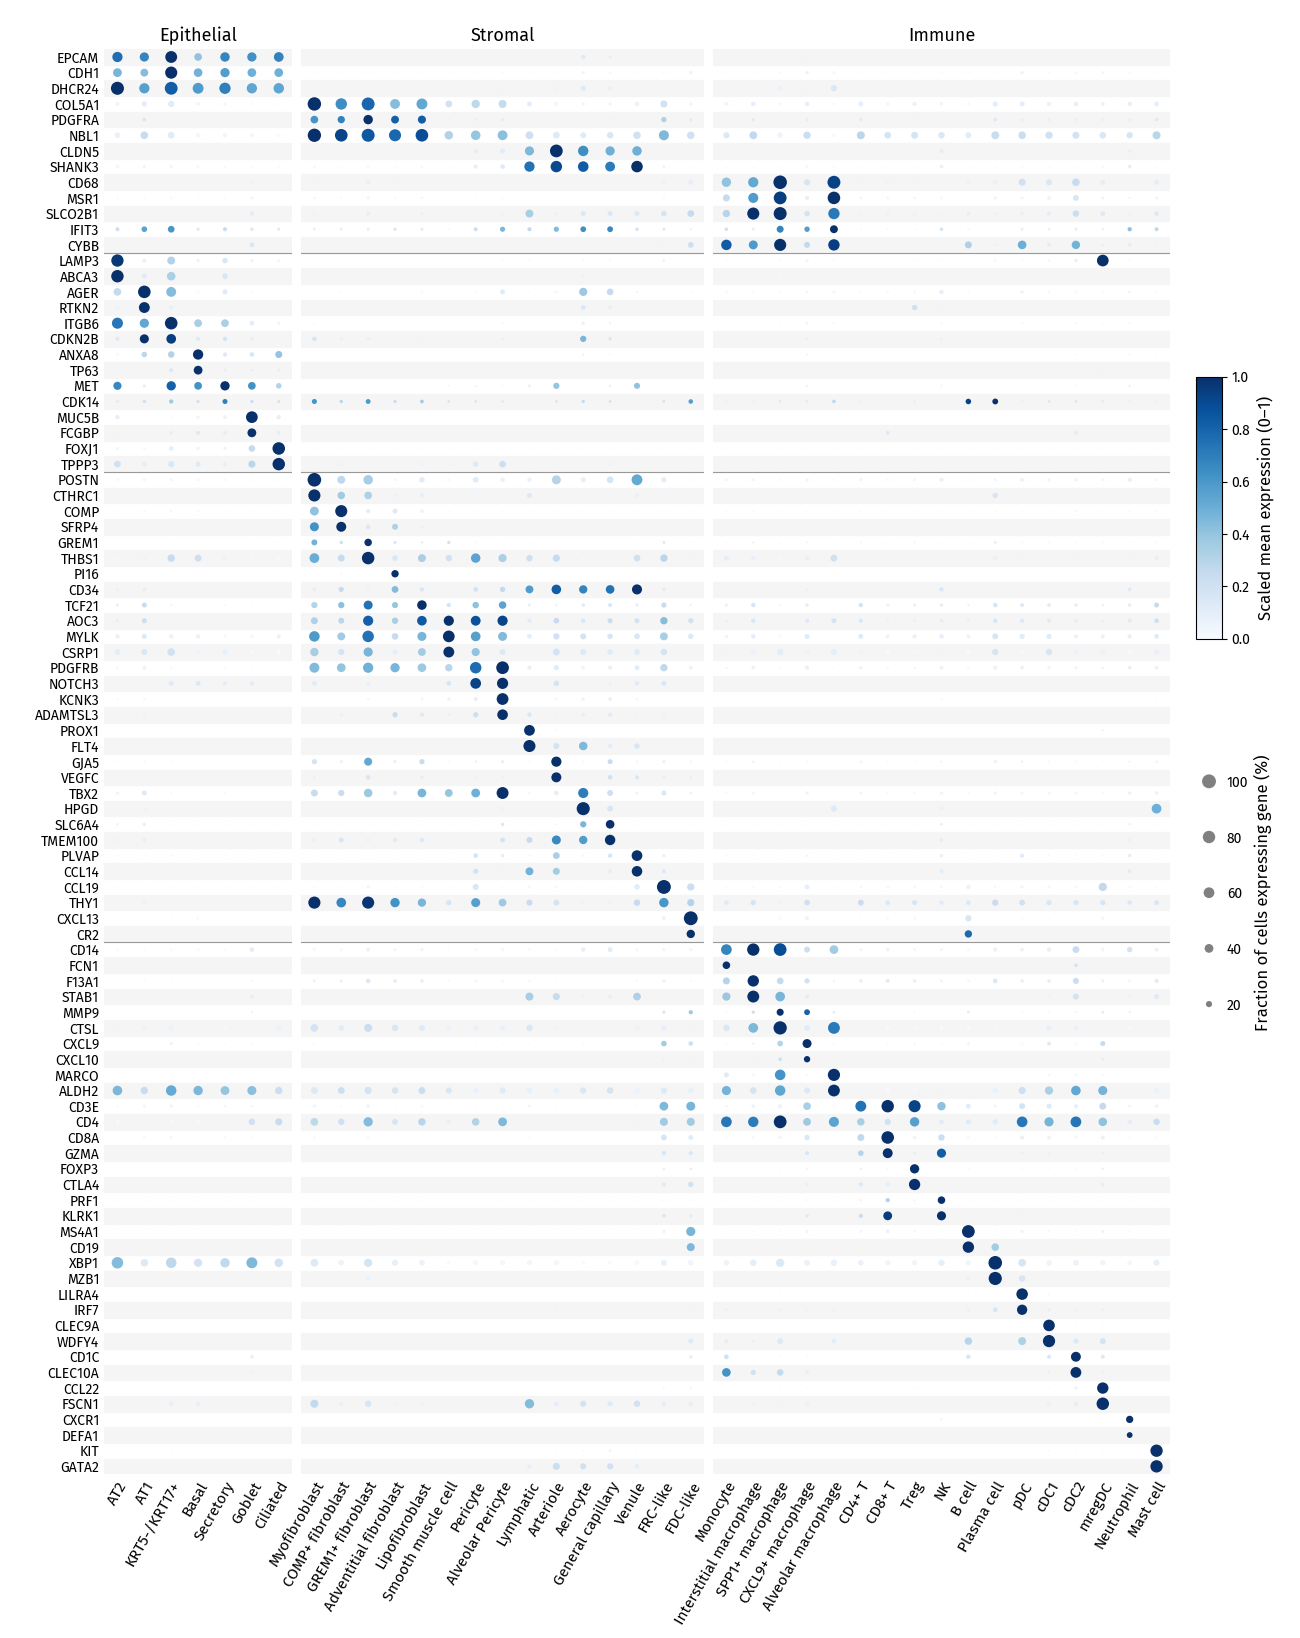

In [12]:

# Dotplot
N_d = len(marker_order)

tp_3m = list(subtype_groups.keys())
wid_r = [len(x) for x in subtype_groups.values()]

fig, axes = plt.subplots(
    1, 3,
    figsize=(13, max(10, N_d * 0.18)),
    width_ratios=wid_r,
    sharey=True
)

fig.subplots_adjust(
    left=0.08,
    top=0.97,
    right=0.90,
    bottom=0.1,
    wspace=0.025
)

size_scale = 100

for n, (ax, tp_3) in enumerate(zip(axes, tp_3m)):

    subtypes = subtype_groups[tp_3]
    N_g = len(subtypes)

    # Subset values in subtype x gene order
    subtype_idx = [
        subtype_order.index(s) for s in subtypes
    ]

    ddf_fractions = fractions[subtype_idx, :]
    ddf_colors = scaled_mean[subtype_idx, :]

    # X axis: cell subtypes
    x = np.repeat(np.arange(N_g), N_d)

    # Y axis: marker genes
    y = np.tile(np.arange(N_d), N_g)

    # Dot size: fraction expressing
    sizes = ddf_fractions.ravel() * size_scale

    # Dot color: scaled mean expression
    colors = ddf_colors.ravel()

    # Alternating row backgrounds
    for iy in range(0, N_d, 2):
        ax.axhspan(
            iy - 0.5, iy + 0.5,
            color="#f5f5f5",
            zorder=0
        )

    # Scatter plot
    sc_fig = ax.scatter(
        x, y,
        s=sizes,
        c=colors,
        cmap="Blues",
        vmin=0,
        vmax=1,
        edgecolors="none",
        zorder=2,
        rasterized=True
    )

    ax.set_xticks(range(N_g))
    ax.set_xticklabels(
        subtypes,
        rotation=60,
        rotation_mode="anchor",
        va="top",
        ha="right",
        fontsize=11
    )

    ax.set_yticks(range(N_d))
    ax.set_xlim(-0.5, N_g - 0.5)
    ax.set_ylim(N_d - 0.5, -0.5)
    ax.set_title(tp_3, fontsize=13)

    # Horizontal boundaries between gene groups
    for yy in gene_boundaries[:-1]:
        ax.axhline(
            yy,
            color="0.6",
            lw=0.8,
            zorder=1
        )

    ax.tick_params(axis="both", length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

# Gene labels on the left panel
axes[0].set_yticklabels(
    marker_order,
    fontsize=10
)

axes[0].tick_params(axis="y", labelleft=True)

for ax in axes[1:]:
    ax.tick_params(axis="y", labelleft=False)

# Colorbar: scaled mean expression
cax = fig.add_axes([0.92, 0.61, 0.02, 0.16])

cbar = fig.colorbar(
    sc_fig,
    cax=cax
)

cbar.set_label(
    "Scaled mean expression (0–1)",
    fontsize=12
)

# Dot size legend
dax = fig.add_axes([0.92, 0.37, 0.02, 0.17])

dax.yaxis.set_label_position("right")
dax.yaxis.set_ticks_position("right")

dax.set_ylabel(
    "Fraction of cells expressing gene (%)",
    fontsize=12
)

legend_fractions = [0.2, 0.4, 0.6, 0.8, 1.0]

dax.scatter(
    [1] * len(legend_fractions),
    range(len(legend_fractions)),
    s=[f * size_scale for f in legend_fractions],
    c="grey",
    edgecolors="none"
)

dax.set_ylim(-0.5, 4.5)
dax.set_xlim(0.5, 1.5)

dax.set_yticks(
    range(len(legend_fractions)),
    labels=["20", "40", "60", "80", "100"]
)

dax.set_xticks([])
dax.tick_params(length=0)
dax.spines[:].set_visible(False)
# for spine in dax.spines.values():
#     spine.set_visible(False)

plt.savefig(f"{WORK_PATH}Figure/015_all_cell_type_marker_dotplot.png", dpi=500, format="png", bbox_inches=None)

In [13]:

records = []

for group_name, subtypes in subtype_groups.items():
    for subtype in subtypes:
        subtype_idx = subtype_order.index(subtype)

        for gene_idx, gene in enumerate(marker_order):
            frac = fractions[subtype_idx, gene_idx]
            expr = scaled_mean[subtype_idx, gene_idx]

            records.append({
                "Cell_type_group": group_name,
                "Cell_subtype": subtype,
                "Marker_gene": gene,
                "Scaled_mean_expression": expr,
                "Fraction_expressing": frac,
                "Fraction_expressing_percent": frac * 100
            })

df_source = pd.DataFrame(records)

group_order = list(subtype_groups.keys())
subtype_rank = {s: i for i, s in enumerate(subtype_order)}
gene_rank = {g: i for i, g in enumerate(marker_order)}
group_rank = {g: i for i, g in enumerate(group_order)}

df_source["__group_rank"] = df_source["Cell_type_group"].map(group_rank)
df_source["__subtype_rank"] = df_source["Cell_subtype"].map(subtype_rank)
df_source["__gene_rank"] = df_source["Marker_gene"].map(gene_rank)

df_source = (
    df_source
    .sort_values(["__group_rank", "__subtype_rank", "__gene_rank"])
    .drop(columns=["__group_rank", "__subtype_rank", "__gene_rank"])
    .reset_index(drop=True)
)

df_source.to_csv(f"{WORK_PATH}CSV/015_all_cell_type_marker_dotplot_source_data.csv", index=True)

# Counting by Cell Type

In [1]:
import pandas as pd
import numpy as np
from Xenium_5K_IPF_constants import CELL_TYPE_3M
import matplotlib.pyplot as plt
from Xenium_5K_IPF_constants import SUBTYPE_HATCHES, WORK_PATH

In [2]:
celltype_df=pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")
celltype_df["3m"] = celltype_df["cell_type_major"].map(CELL_TYPE_3M)
tp_3m = ["Epithelial", "Stromal", "Immune"]
m_df = [celltype_df[celltype_df["3m"]==tp_3].value_counts("subtype") for tp_3 in tp_3m]

In [3]:
df = pd.crosstab(celltype_df["subtype"], celltype_df["sample"])
df_rt = 100*df/df.sum()
df_rt=df_rt.reindex(index=list(SUBTYPE_HATCHES))
df_rt.to_csv(f"{WORK_PATH}CSV/015_alltype_counts_by_sample.csv", encoding="utf-8-sig")

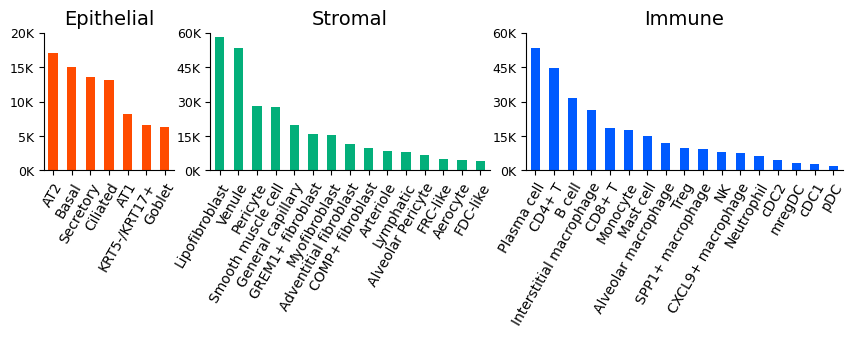

In [4]:
fig, axes = plt.subplots(1,3, width_ratios=[len(m_df[n]) for n in [0,1,2]], figsize=(8.5,3.2))
plt.subplots_adjust(left=0.05, right=0.99, bottom=0.47, top=0.9, wspace=0.15)
[m_df[n].plot.bar(ax=axes[n], color=c) for n,c in enumerate(["#ff4b00", "#03af7a", "#005aff"])]
[ax.set_xlabel("") for ax in axes]
[ax.set_title(t, weight=500, fontsize=14) for ax,t in zip(axes,["Epithelial", "Stromal", "Immune"])]

vmax = [m.max() for m in m_df]

for ax, vm in zip(axes, vmax):
    v_lim = ((vm//20e3)+1)*20e3 
    ax.set_ylim(0,v_lim)
    yticks = np.linspace(0, v_lim, 5)
    ax.set_yticks(ticks=[y for y in yticks], labels=[f"{int(y/1000)}K" for y in yticks], fontsize=9)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=60, rotation_mode="anchor", va="top", ha="right", fontsize=10)

plt.savefig(f"{WORK_PATH}Figure/015_all_celltype_counts.png", dpi=500, format="png", bbox_inches=None)
plt.show()

In [16]:
df_source = pd.DataFrame(columns=["major lineage", "subtype", "count"])
a = 0
for n, m3 in enumerate(tp_3m):
    for s, c in m_df[n].items():
        df_source.loc[a, "major lineage"]=m3
        df_source.loc[a, "subtype"]= s
        df_source.loc[a, "count"]=c
        a += 1
    

df_source.to_csv(f"{WORK_PATH}CSV/015_all_celltype_counts_source_data.csv", index=True)

# Neighborfood Ennrichment Analysis by Squidpy

In [15]:
import scanpy as sc
import squidpy as sq
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram, set_link_color_palette
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scicm
import pandas as pd
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, WORK_PATH

# Option
sc.settings.verbosity = 3
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

/home/s_nakamura/test_env/lib/python3.12/site-packages/scicm/cm.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pkg_resources


In [16]:
celltype_df=pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/spatial_merged.h5ad")

In [17]:
adata = adata[celltype_df.index, ].copy()
adata.obs["subtype"]=celltype_df["subtype"]
adata.obs["subtype"]=pd.Categorical(values=adata.obs["subtype"], categories=ALL_SUBTYPE_LIST, ordered=True)

In [18]:
sq.gr.spatial_neighbors(adata, coord_type="generic", delaunay=True)
sq.gr.nhood_enrichment(adata, cluster_key="subtype")

INFO     Creating graph using `generic` coordinates and `None` transform and `1` libraries.                        
Adding `adata.obsp['spatial_connectivities']`
       `adata.obsp['spatial_distances']`
       `adata.uns['spatial_neighbors']`
Calculating neighborhood enrichment using `1` core(s)


  0%|          | 0/1000 [00:00<?, ?/s]

Adding `adata.uns['subtype_nhood_enrichment']`
Finish (0:00:46)


In [19]:
subtypes = list(adata.obs["subtype"].cat.categories)
Z = pd.DataFrame(adata.uns["subtype_nhood_enrichment"]["zscore"], index=subtypes, columns=subtypes)

In [20]:
# Hierarchical clustering
D = pdist(Z.values, metric="correlation")
L = linkage(D, method="average")
ordered_labels = Z.index[leaves_list(L)]
Z_reordered = Z.loc[ordered_labels, ordered_labels]
n = len(ordered_labels)

In [21]:
# Color scale
offdiag = Z.values[~np.eye(len(Z), dtype=bool)]
zlim = max(1.0, float(np.ceil(np.nanpercentile(np.abs(offdiag), 99.5))))
print("Color scale:", -zlim, zlim)
norm = matplotlib.colors.TwoSlopeNorm(vmin=-zlim, vcenter=0, vmax=zlim)
cmap = plt.get_cmap("RdBu_r").copy()

Color scale: -176.0 176.0


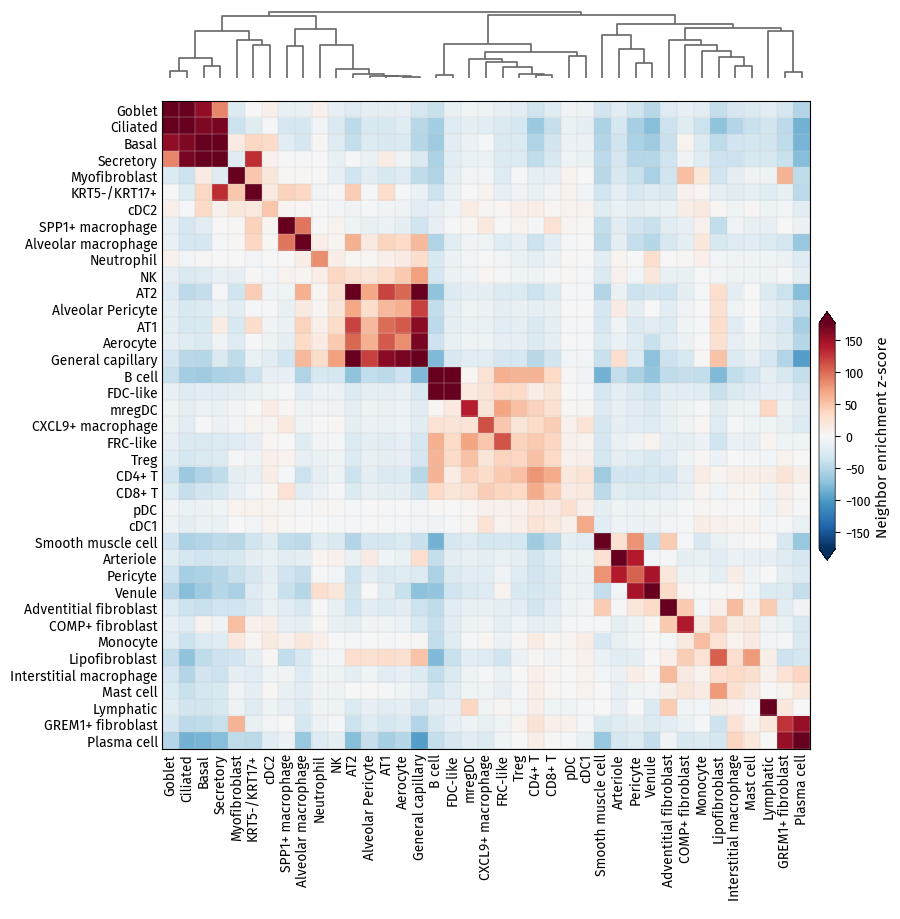

In [22]:
# Plot
fig = plt.figure(figsize=(9, 9.2))
gs = fig.add_gridspec(
    2, 1,
    height_ratios=[1, 10],
    left=0.18,
    right=0.9,
    bottom=0.16,
    top=0.99,
    hspace=0
)

ax_dendro = fig.add_subplot(gs[0])
ax_heatmap = fig.add_subplot(gs[1])

# Dendrogram
dendrogram(
    L,
    orientation="top",
    no_labels=True,
    ax=ax_dendro,
    color_threshold=0,
    above_threshold_color="#666666"
)

for line in ax_dendro.collections:
    line.set_linewidth(1.2)

ax_dendro.axis("off")

# Heatmap
im = ax_heatmap.imshow(
    Z_reordered.values,
    cmap=cmap,
    norm=norm,
    aspect="equal",
    interpolation="nearest",
    origin="upper"
)

# X-axis
ax_heatmap.set_xticks(np.arange(n))
ax_heatmap.set_xticklabels(
    ordered_labels,
    rotation=90,
    ha="center",
    fontsize=10
)

# Y-axis
ax_heatmap.set_yticks(np.arange(n))
ax_heatmap.set_yticklabels(ordered_labels, fontsize=10)

# Others
ax_heatmap.tick_params(axis="both", length=0, pad=3)
ax_heatmap.set_xticks(np.arange(-0.5, n, 1), minor=True)
ax_heatmap.set_yticks(np.arange(-0.5, n, 1), minor=True)

ax_heatmap.grid(which="minor", color="#CCCCCC", linewidth=0.25)
ax_heatmap.tick_params(which="minor", bottom=False, left=False)

# colorbar
cax = fig.add_axes([0.91, 0.39, 0.018, 0.27])
cbar = fig.colorbar(im, cax=cax, extend="both")
cbar.set_label("Neighbor enrichment z-score", fontsize=11)
cbar.ax.tick_params(labelsize=9)
cbar.outline.set_linewidth(0.5)

fig.savefig(f"{WORK_PATH}Figure/015_neighbor_enrichment_score.png", dpi=500, bbox_inches="tight")


In [23]:
df_source = Z_reordered.copy()

df_source.index = ordered_labels
df_source.columns = ordered_labels

df_source.index.name = "Cell_subtype"


df_source.to_csv(f"{WORK_PATH}CSV/015_neighbor_enrichment_score_source_data.csv", index=True)

# Enrichment Analysis by Each Subtype

In [ ]:
import scanpy as sc
import decoupler as dc
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, WORK_PATH

# Option
sc.settings.verbosity = 3
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

In [ ]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/integrated_anndata.h5ad")
celltype_df=pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")

In [ ]:
adata.obs = pd.merge(adata.obs, celltype_df[["subtype", "cell_type_major"]], left_index=True, right_index=True, how="left")

In [ ]:
progeny = dc.op.progeny(organism="human")

In [ ]:
dc.mt.mlm(data=adata, net=progeny)
score = dc.pp.get_obsm(adata=adata, key="score_mlm")

In [ ]:
df = score.to_df()
df["subtype"]=score.obs["subtype"]
cluster_df = df.groupby("subtype").mean()
cluster_df = cluster_df.loc[ALL_SUBTYPE_LIST]

In [ ]:
sns.clustermap(
    data=cluster_df,
    z_score=1,
    dendrogram_ratio=(0,0.05),
    method="average",
    row_cluster=False,
    cmap="PuOr_r",
    figsize=(5.5,10),
    vmax=4, vmin=-2.5,
    cbar_kws={"orientation":"horizontal", "ticks":[-2, 0 ,2, 4]}
)
plt.subplots_adjust(right=0.6, bottom=0.18)

chi = plt.gcf().get_children()
chi[3].tick_params("y", labelsize=13)
chi[3].tick_params("x", labelsize=13)
chi[3].set_xlabel("")
chi[3].set_ylabel("")
chi[4].set_position((0.7, 0.072, 0.2, 0.025))
chi[4].tick_params("x", labelsize=12)
chi[4].set_title("Z-score\n(for pathways)", fontsize=13)

for ch in [chi[1], chi[2]]:
    line_c = [c for c in ch.get_children() if isinstance(c, matplotlib.collections.LineCollection)]
    for l_c in line_c:
        l_c.set(linewidth=1)
    
plt.savefig(f"{WORK_PATH}Figure/015_subtype_enrichment_Progeny.png", dpi=500, format="png", bbox_inches=None)